# Chapter 11: The lift

Checks [chapter 11](../../book/11-the-lift.md). The model is **linear in its weights**: it lifts the input to
a list of features and takes the dot product with the weights. The stand-in is the **Fourier lift**, the pair
`(cos(frequency * input), sin(frequency * input))` for each of a list of fixed frequencies, with the cosine and
sine coefficients as the weights (linear). The bump experiment uses the Gaussian bump lift of
`RadialBasis.lean`. Everything is NumPy in float64, seeded. These are measurements, not proofs: the proofs are in
`Lift.lean`, `FourierLift.lean`, `RadialBasis.lean` and `RandomFourier.lean`.

Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 11


def lift_by_fourier(inputs, frequencies):
    """Rows are inputs; columns are cos(frequency * input), sin(frequency * input) for each frequency."""
    angles = np.outer(inputs, frequencies)
    return np.concatenate([np.cos(angles), np.sin(angles)], axis=1)


def get_lift_kernel(inputs, other_inputs, frequencies):
    """The overlap of two lifted inputs, computed from the features."""
    return lift_by_fourier(inputs, frequencies) @ lift_by_fourier(other_inputs, frequencies).T


def evaluate_lifted_model(inputs, weights, frequencies):
    return lift_by_fourier(inputs, frequencies) @ weights

## Claim 1: the slope of a lifted model is at most the size of the weights times the stretch of the lift (`lipschitzWith_liftedModel`, `lipschitzWith_fourierLift`)

For one frequency the lift stretches distances by at most that frequency. For a stack of frequencies the lift
`(cos, sin)` of all of them stretches by at most `sqrt(sum of frequency^2)`, which is the stretch used for the
multi-frequency rows. For 2000 random weight vectors, with 1 to 8 random frequencies, we take 400 random
pairs of inputs and measure the steepest chord `|model(x) - model(y)| / |x - y|`. It must stay below
`norm(weights) * stretch`. A control shows the check can fail: half that bound is broken in many trials, so the
bound is not slack. Then one frequency alone: the stretch of the lift itself must be at most the frequency, and
come close to it.

In [2]:
generator = np.random.default_rng(SEED)
ratios = []
bounds = []
steepest = []
broken_by_half = 0
for trial in range(2000):
    num_frequencies = int(generator.integers(1, 9))
    frequencies = generator.uniform(0.5, 12.0, size=num_frequencies)
    weights = generator.standard_normal(2 * num_frequencies)
    stretch = np.sqrt(np.sum(frequencies ** 2))
    bound = np.linalg.norm(weights) * stretch
    first = generator.uniform(-3, 3, size=400)
    second = first + generator.uniform(-0.3, 0.3, size=400)
    chords = np.abs(evaluate_lifted_model(first, weights, frequencies)
                    - evaluate_lifted_model(second, weights, frequencies)) / np.abs(first - second)
    ratios.append(chords.max() / bound)
    bounds.append(bound)
    steepest.append(chords.max())
    broken_by_half += chords.max() > 0.5 * bound
report("steepest chord <= norm(weights) * stretch in all 2000 trials", max(ratios) <= 1.0,
       f"largest ratio {max(ratios):.3f}")
report("control: half the bound is broken (the bound is not slack)", broken_by_half > 0,
       f"broken in {broken_by_half} of 2000")

lift_ratios = []
for frequency in (1.0, 3.0, 10.0, 40.0):
    first = generator.uniform(-3, 3, size=5000)
    second = first + generator.uniform(-0.2, 0.2, size=5000)
    distance_between_lifts = np.linalg.norm(lift_by_fourier(first, [frequency]) - lift_by_fourier(second, [frequency]), axis=1)
    lift_ratios.append((distance_between_lifts / np.abs(first - second)).max() / frequency)
report("one frequency: lift stretch <= frequency, and gets above 0.99 of it",
       max(lift_ratios) <= 1.0 + 1e-12 and min(lift_ratios) > 0.99, str([f"{value:.4f}" for value in lift_ratios]))

[PASS] steepest chord <= norm(weights) * stretch in all 2000 trials  (largest ratio 1.000)
[PASS] control: half the bound is broken (the bound is not slack)  (broken in 1730 of 2000)
[PASS] one frequency: lift stretch <= frequency, and gets above 0.99 of it  (['1.0000', '1.0000', '1.0000', '1.0000'])


True

wrote book/figures/11-slope-bound.png


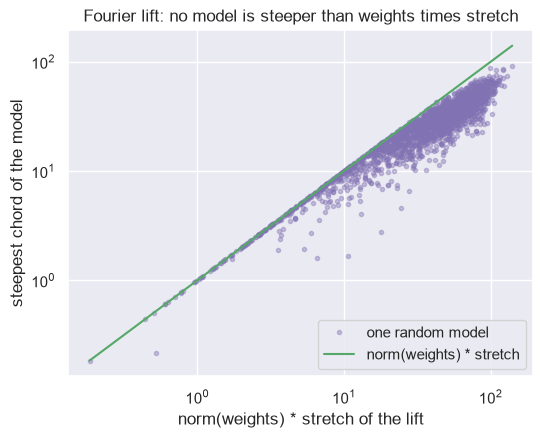

In [3]:
figure, axis = plt.subplots(figsize=(6, 4.5))
axis.loglog(bounds, steepest, ".", color=MODEL, alpha=0.4, label="one random model")
line = np.array([min(bounds), max(bounds)])
axis.loglog(line, line, color=BOUND, label="norm(weights) * stretch")
axis.set_xlabel("norm(weights) * stretch of the lift")
axis.set_ylabel("steepest chord of the model")
axis.set_title("Fourier lift: no model is steeper than weights times stretch")
axis.legend(loc="lower right")
save_figure(figure, "11-slope-bound")
plt.show()

## Claim 2: the kernel trick (`liftedModel_add_sum`)

Take 8 data points and 20 frequencies (40 weights), a **random start** `start_weights`, and run gradient descent on
the squared error `0.5 * mean(residual^2)`. In weight space each step is `weights += step_size * features.T @ residual / 8`.
Now run the same descent **without the features**: keep one coefficient per data point and update
`coefficients += step_size * residual / 8`, where the residual uses
`start_prediction + kernel_matrix @ coefficients`. At the end the prediction at 50 new inputs must be
`start_prediction(new) + kernel(new, data) @ coefficients`, equal to the prediction from the weights. The features are
not used in the second route (the kernel entries are the overlaps, which by claim 3 are `cos(frequency * gap)` summed).
Controls: changing one coefficient by 1% breaks the match, and leaving out the starting prediction breaks it.

In [4]:
generator = np.random.default_rng(SEED + 1)
NUM_DATA = 8
frequencies = np.arange(1, 21, dtype=float) * 0.7
data_inputs = np.sort(generator.uniform(-3, 3, NUM_DATA))
labels = generator.standard_normal(NUM_DATA)
new_inputs = np.linspace(-4, 4, 50)
start_weights = generator.standard_normal(2 * len(frequencies))

data_features = lift_by_fourier(data_inputs, frequencies)
kernel_matrix = get_lift_kernel(data_inputs, data_inputs, frequencies)
step_size = 1.0 / (np.linalg.norm(kernel_matrix, 2) / NUM_DATA)

weights = start_weights.copy()
coefficients = np.zeros(NUM_DATA)
start_prediction_on_data = evaluate_lifted_model(data_inputs, start_weights, frequencies)
NUM_STEPS = 300
for step in range(NUM_STEPS):
    residual = labels - data_features @ weights
    weights = weights + step_size * data_features.T @ residual / NUM_DATA
    kernel_residual = labels - (start_prediction_on_data + kernel_matrix @ coefficients)
    coefficients = coefficients + step_size * kernel_residual / NUM_DATA

start_prediction_on_new = evaluate_lifted_model(new_inputs, start_weights, frequencies)
prediction_from_weights = evaluate_lifted_model(new_inputs, weights, frequencies)
cross_kernel = new_inputs[:, None] - data_inputs[None, :]
cross_kernel = np.cos(cross_kernel[:, :, None] * frequencies[None, None, :]).sum(axis=2)   # no features used
prediction_from_kernel = start_prediction_on_new + cross_kernel @ coefficients
gap_size = np.abs(prediction_from_weights - prediction_from_kernel).max()
movement = np.abs(prediction_from_weights - start_prediction_on_new).max()
report("prediction at 50 new inputs = start prediction + sum of coefficient * kernel, after 300 steps",
       gap_size < 1e-9, f"largest gap {gap_size:.1e}; the prediction moved by {movement:.2f}")
report("training really moved things (the check is not about a frozen model)", movement > 0.5)

nudged = coefficients.copy()
nudged[3] *= 1.01
nudged_gap = np.abs(start_prediction_on_new + cross_kernel @ nudged - prediction_from_weights).max()
report("control: a 1% change to one coefficient breaks the match", nudged_gap > 1e-4, f"gap {nudged_gap:.1e}")
no_start_gap = np.abs(cross_kernel @ coefficients - prediction_from_weights).max()
report("control: leaving out the starting prediction breaks the match", no_start_gap > 1e-2, f"gap {no_start_gap:.2f}")
moved = weights - start_weights
off_span = moved - data_features.T @ np.linalg.lstsq(data_features.T, moved, rcond=None)[0]
report("the weights moved only along the lifted data points", np.linalg.norm(off_span) < 1e-9,
       f"off-span part {np.linalg.norm(off_span):.1e}")

[PASS] prediction at 50 new inputs = start prediction + sum of coefficient * kernel, after 300 steps  (largest gap 2.0e-14; the prediction moved by 6.74)
[PASS] training really moved things (the check is not about a frozen model)
[PASS] control: a 1% change to one coefficient breaks the match  (gap 1.1e-02)
[PASS] control: leaving out the starting prediction breaks the match  (gap 8.72)
[PASS] the weights moved only along the lifted data points  (off-span part 4.2e-15)


True

## Claim 3: the Fourier kernel is `cos(frequency * gap)`, and shifting everything together changes nothing (`liftKernel_fourierLift`)

First the features: for one frequency, the dot product of the lifts of `x` and `y` is compared with
`cos(frequency * (x - y))` on 5000 random pairs. Then the shift: add one number to the data and to the
question. The kernel matrix, and the kernel-trick prediction from a zero start, must not change.
The control is a kernel that is not of the gap, the plain product `x * y`: shifting breaks it.

In [5]:
generator = np.random.default_rng(SEED + 2)
first = generator.uniform(-5, 5, 5000)
second = generator.uniform(-5, 5, 5000)
worst = 0.0
for frequency in (0.3, 1.0, 7.5):
    from_features = np.sum(lift_by_fourier(first, [frequency]) * lift_by_fourier(second, [frequency]), axis=1)
    worst = max(worst, np.abs(from_features - np.cos(frequency * (first - second))).max())
report("lift . lift = cos(frequency * gap) for 3 frequencies x 5000 pairs", worst < 1e-12, f"largest error {worst:.1e}")


def predict_by_kernel_trick(data_inputs, labels, new_inputs, frequencies, num_steps=300):
    """Zero start, kernel only: gradient descent on the coefficients, then the cross kernel."""
    kernel_matrix = get_lift_kernel(data_inputs, data_inputs, frequencies)
    step_size = 1.0 / (np.linalg.norm(kernel_matrix, 2) / len(labels))
    coefficients = np.zeros(len(labels))
    for step in range(num_steps):
        coefficients = coefficients + step_size * (labels - kernel_matrix @ coefficients) / len(labels)
    return get_lift_kernel(new_inputs, data_inputs, frequencies) @ coefficients


kernel_gaps = []
shift_gaps = []
product_gaps = []
for shift in (-7.3, 0.4, 25.0, 1000.0):
    shifted_matrix = get_lift_kernel(data_inputs + shift, data_inputs + shift, frequencies)
    kernel_gaps.append(np.abs(shifted_matrix - kernel_matrix).max())
    before = predict_by_kernel_trick(data_inputs, labels, new_inputs, frequencies)
    after = predict_by_kernel_trick(data_inputs + shift, labels, new_inputs + shift, frequencies)
    shift_gaps.append(np.abs(after - before).max())
    product_gaps.append(np.abs(np.outer(data_inputs + shift, data_inputs + shift) - np.outer(data_inputs, data_inputs)).max())
report("kernel matrix unchanged by a shift of the data (4 shifts up to 1000)", max(kernel_gaps) < 1e-9, f"largest change {max(kernel_gaps):.1e}")
report("prediction unchanged when data and question are shifted together", max(shift_gaps) < 1e-9, f"largest change {max(shift_gaps):.1e}")
report("control: the product kernel x * y changes under the same shifts", min(product_gaps) > 1.0, f"smallest change {min(product_gaps):.2f}")

[PASS] lift . lift = cos(frequency * gap) for 3 frequencies x 5000 pairs  (largest error 1.6e-14)
[PASS] kernel matrix unchanged by a shift of the data (4 shifts up to 1000)  (largest change 6.0e-12)
[PASS] prediction unchanged when data and question are shifted together  (largest change 3.1e-12)
[PASS] control: the product kernel x * y changes under the same shifts  (smallest change 2.30)


True

## Claim 4: bumps (`lipschitzWith_bump`, `lipschitzWith_bumpNetwork`, `exists_heights_of_gap`)

The bump is `exp(-(offset / width)^2 / 2)`. (a) The steepest slope of one bump, found on a fine grid, must be at most
`1 / width` (the true value is `1 / (width * sqrt(e))`, as the Lean comment notes). A bump network's slope must be at most
`sum(abs(heights)) / width`. (b) Take 10 inputs with minimum spacing `gap` and random labels. When
`(count - 1) * exp(-(gap / width)^2 / 2) < 1`, which holds for narrow enough bumps, the network with a bump on each
input must fit the labels exactly after solving for the heights. We sweep the width and report whether the
theorem's condition holds, the fit error, and the total height needed.

In [6]:
generator = np.random.default_rng(SEED + 3)


def get_bump(offsets, width):
    return np.exp(-(offsets / width) ** 2 / 2)


grid = np.linspace(-5, 5, 400001)
slope_ratios = []
for width in (0.05, 0.1, 0.5, 1.0, 2.0):
    values = get_bump(grid, width)
    steepest_slope = np.abs(np.diff(values) / np.diff(grid)).max()
    slope_ratios.append(steepest_slope * width)
report("one bump: steepest slope <= 1 / width, and equals 1/sqrt(e) / width",
       max(slope_ratios) <= 1.0 and np.allclose(slope_ratios, np.exp(-0.5), atol=1e-3),
       f"slope * width = {slope_ratios[0]:.4f} for all widths")

network_ratios = []
for trial in range(200):
    width = generator.uniform(0.05, 2.0)
    centres = generator.uniform(-3, 3, 6)
    heights = generator.standard_normal(6) * 3
    fine_inputs = np.linspace(-4, 4, 20001)
    values = sum(height * get_bump(fine_inputs - centre, width) for height, centre in zip(heights, centres))
    network_ratios.append((np.abs(np.diff(values) / np.diff(fine_inputs)).max()) / (np.abs(heights).sum() / width))
report("bump network: steepest slope <= sum(abs(heights)) / width in 200 random networks", max(network_ratios) <= 1.0,
       f"largest ratio {max(network_ratios):.3f}")

NUM_BUMP_DATA = 10
inputs = np.arange(NUM_BUMP_DATA) * 0.5 + generator.uniform(-0.1, 0.1, NUM_BUMP_DATA)
GAP = np.abs(np.diff(inputs)).min()
bump_labels = generator.standard_normal(NUM_BUMP_DATA)
widths = np.array([0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0])
rows = []
for width in widths:
    overlap = (NUM_BUMP_DATA - 1) * np.exp(-(GAP / width) ** 2 / 2)
    bump_matrix = get_bump(inputs[:, None] - inputs[None, :], width)
    heights = np.linalg.solve(bump_matrix, bump_labels)
    fit_error = np.abs(bump_matrix @ heights - bump_labels).max()
    rows.append((width, overlap, fit_error, np.abs(heights).sum(), np.abs(heights).sum() / width))
print(f"{'width':>6} {'overlap':>9} {'fit error':>10} {'sum |height|':>13} {'slope limit':>12}")
for width, overlap, fit_error, total_height, slope_limit in rows:
    print(f"{width:>6} {overlap:>9.2e} {fit_error:>10.1e} {total_height:>13.3g} {slope_limit:>12.3g}")
narrow = [row for row in rows if row[1] < 1]
report("whenever (count - 1) * worst bump < 1, the fit is exact", len(narrow) >= 3 and all(row[2] < 1e-9 for row in narrow),
       f"{len(narrow)} widths meet the condition, worst fit error {max(row[2] for row in narrow):.1e}")
report("narrow bumps: heights are about the labels (total height under 3 * sum of labels)",
       rows[0][3] < 3 * np.abs(bump_labels).sum(), f"width 0.02 total height {rows[0][3]:.2f} vs labels {np.abs(bump_labels).sum():.2f}")
report("wide bumps pay: the total height needed is over 1000 times larger at width 1.0 than at width 0.1",
       rows[6][3] > 1000 * rows[2][3], f"{rows[2][3]:.2f} -> {rows[6][3]:.3g}")

[PASS] one bump: steepest slope <= 1 / width, and equals 1/sqrt(e) / width  (slope * width = 0.6065 for all widths)


[PASS] bump network: steepest slope <= sum(abs(heights)) / width in 200 random networks  (largest ratio 0.574)
 width   overlap  fit error  sum |height|  slope limit
  0.02  5.37e-61    0.0e+00          6.57          329
  0.05  1.44e-09    0.0e+00          6.57          131
   0.1  3.20e-02    1.4e-17          6.58         65.8
   0.2  2.20e+00    2.2e-16          7.22         36.1
   0.3  4.81e+00    4.4e-16          10.6         35.3
   0.5  7.18e+00    4.4e-15          81.7          163
   1.0  8.51e+00    2.3e-11      4.74e+05     4.74e+05
   2.0  8.87e+00    7.5e-06      7.18e+10     3.59e+10
[PASS] whenever (count - 1) * worst bump < 1, the fit is exact  (3 widths meet the condition, worst fit error 1.4e-17)
[PASS] narrow bumps: heights are about the labels (total height under 3 * sum of labels)  (width 0.02 total height 6.57 vs labels 6.57)
[PASS] wide bumps pay: the total height needed is over 1000 times larger at width 1.0 than at width 0.1  (6.58 -> 4.74e+05)


True

wrote book/figures/11-bump-width.png


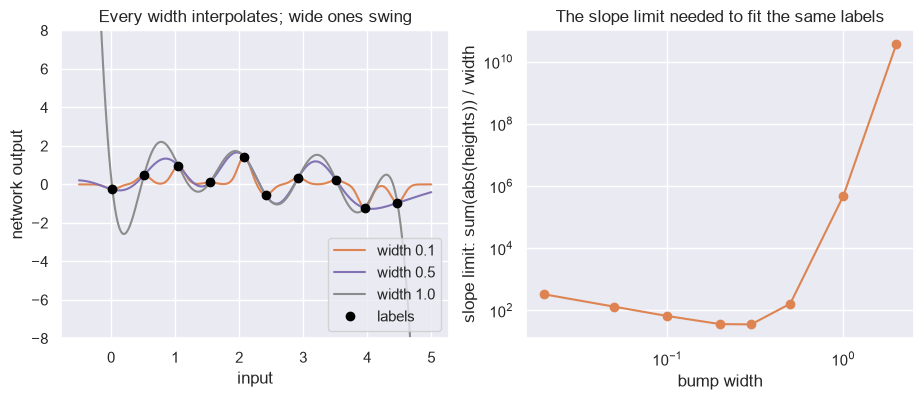

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
inputs_fine = np.linspace(-0.5, 5.0, 2000)
for width, color in ((0.1, VERTICAL), (0.5, MODEL), (1.0, BEFORE)):
    bump_matrix = get_bump(inputs[:, None] - inputs[None, :], width)
    heights = np.linalg.solve(bump_matrix, bump_labels)
    axes[0].plot(inputs_fine, sum(height * get_bump(inputs_fine - centre, width) for height, centre in zip(heights, inputs)),
                 color=color, label=f"width {width}")
axes[0].plot(inputs, bump_labels, "o", color="black", label="labels")
axes[0].set_ylim(-8, 8)
axes[0].set_xlabel("input")
axes[0].set_ylabel("network output")
axes[0].set_title("Every width interpolates; wide ones swing")
axes[0].legend(loc="lower right")
axes[1].loglog([row[0] for row in rows], [row[4] for row in rows], "o-", color=VERTICAL)
axes[1].set_xlabel("bump width")
axes[1].set_ylabel("slope limit: sum(abs(heights)) / width")
axes[1].set_title("The slope limit needed to fit the same labels")
save_figure(figure, "11-bump-width")
plt.show()

## Claim 5: averaged over bell-curve frequencies, the Fourier kernel is the bump (`integral_liftKernel_fourierLift`)

Draw `count` frequencies from a normal distribution with the given `variance`. The average of
`cos(frequency * gap)` over them should be near `exp(-variance * gap^2 / 2)`. For 3 variances and 5 gaps, the root
mean squared error should shrink as `count` grows. Theory says the error falls like one over the square root of
`count`, so a log-log fit should have slope near `-0.5`; that is measured here, not stated by the Lean theorem, which
is about the exact average (an integral). A control that must fail: frequencies drawn uniformly with the same
variance do not give the bump.

In [8]:
generator = np.random.default_rng(SEED + 4)
COUNTS = (10, 100, 1000, 10000, 100000)
VARIANCES = (0.5, 2.0, 9.0)
GAPS = np.array([0.1, 0.3, 0.6, 1.0, 1.5])
errors = {}
for variance in VARIANCES:
    target = np.exp(-variance * GAPS ** 2 / 2)
    for count in COUNTS:
        repeats = 200 if count <= 1000 else 40
        draws = generator.normal(0.0, np.sqrt(variance), size=(repeats, count))
        averages = np.cos(draws[:, :, None] * GAPS[None, None, :]).mean(axis=1)
        errors[variance, count] = np.sqrt(np.mean((averages - target) ** 2))
print(f"{'variance':>8} " + " ".join(f"{count:>9}" for count in COUNTS))
for variance in VARIANCES:
    print(f"{variance:>8} " + " ".join(f"{errors[variance, count]:>9.5f}" for count in COUNTS))
for variance in VARIANCES:
    series = [errors[variance, count] for count in COUNTS]
    slope = np.polyfit(np.log(COUNTS), np.log(series), 1)[0]
    report(f"variance {variance}: error falls at every step and the log-log slope is near -0.5",
           all(later < earlier for earlier, later in zip(series, series[1:])) and -0.65 < slope < -0.35,
           f"error {series[0]:.4f} -> {series[-1]:.5f}, slope {slope:.2f}")
report("with 100000 frequencies the error is under 0.005 everywhere", max(errors[variance, COUNTS[-1]] for variance in VARIANCES) < 0.005)

variance = 2.0
uniform_draws = generator.uniform(-np.sqrt(3 * variance), np.sqrt(3 * variance), size=(40, 100000))
uniform_averages = np.cos(uniform_draws[:, :, None] * GAPS[None, None, :]).mean(axis=1)
uniform_error = np.sqrt(np.mean((uniform_averages - np.exp(-variance * GAPS ** 2 / 2)) ** 2))
report("control: frequencies drawn uniformly with the same variance miss the bump", uniform_error > 0.02,
       f"error {uniform_error:.3f} against {errors[variance, 100000]:.5f} for the bell curve")

variance        10       100      1000     10000    100000
     0.5   0.07836   0.02829   0.00809   0.00207   0.00073
     2.0   0.13880   0.04503   0.01404   0.00447   0.00141
     9.0   0.18166   0.05667   0.01763   0.00521   0.00161
[PASS] variance 0.5: error falls at every step and the log-log slope is near -0.5  (error 0.0784 -> 0.00073, slope -0.52)
[PASS] variance 2.0: error falls at every step and the log-log slope is near -0.5  (error 0.1388 -> 0.00141, slope -0.50)
[PASS] variance 9.0: error falls at every step and the log-log slope is near -0.5  (error 0.1817 -> 0.00161, slope -0.51)
[PASS] with 100000 frequencies the error is under 0.005 everywhere


[PASS] control: frequencies drawn uniformly with the same variance miss the bump  (error 0.120 against 0.00141 for the bell curve)


True

wrote book/figures/11-random-fourier.png


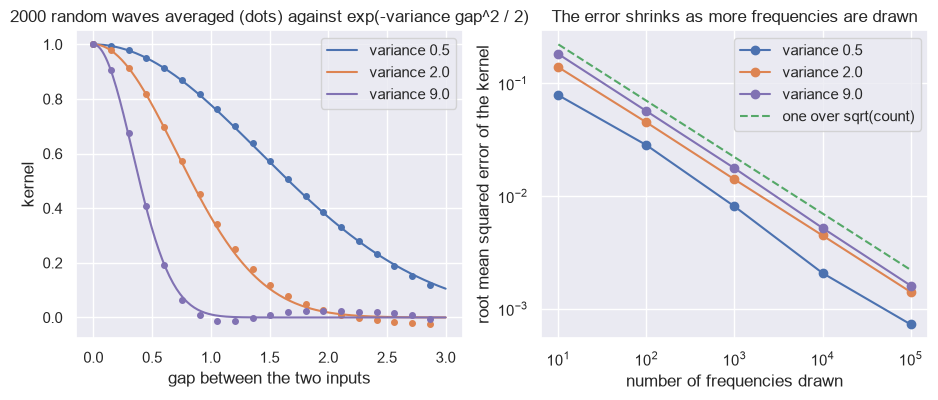

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
fine_gaps = np.linspace(0, 3, 200)
colors = (NEAREST, VERTICAL, MODEL)
for variance, color in zip(VARIANCES, colors):
    axes[0].plot(fine_gaps, np.exp(-variance * fine_gaps ** 2 / 2), color=color, label=f"variance {variance}")
    draws = generator.normal(0.0, np.sqrt(variance), size=2000)
    axes[0].plot(fine_gaps[::10], np.cos(draws[:, None] * fine_gaps[None, ::10]).mean(axis=0), "o", color=color, markersize=4)
axes[0].set_xlabel("gap between the two inputs")
axes[0].set_ylabel("kernel")
axes[0].set_title("2000 random waves averaged (dots) against exp(-variance gap^2 / 2)")
axes[0].legend()
for variance, color in zip(VARIANCES, colors):
    axes[1].loglog(COUNTS, [errors[variance, count] for count in COUNTS], "o-", color=color, label=f"variance {variance}")
axes[1].loglog(COUNTS, 0.7 / np.sqrt(COUNTS), "--", color=BOUND, label="one over sqrt(count)")
axes[1].set_xlabel("number of frequencies drawn")
axes[1].set_ylabel("root mean squared error of the kernel")
axes[1].set_title("The error shrinks as more frequencies are drawn")
axes[1].legend()
save_figure(figure, "11-random-fourier")
plt.show()